In [ ]:
import os
os.makedirs("Air_Quality_Classification", exist_ok=True)

In [ ]:
import pandas as pd

df = pd.read_csv("/content/Air_Quality_Classification/dataset.csv")

df.head()

,670,696,1252,1720,1321,2431,4
0,641,674,1156,1652,1410,2433,4
1,642,646,1159,1643,1455,2361,4
2,640,590,1105,1608,1459,2427,4
3,616,627,1192,1637,1466,2447,4
4,780,896,1438,1813,1489,2434,4


In [ ]:
df.columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1844 entries, 0 to 1843
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   670     1844 non-null   int64
 1   696     1844 non-null   int64
 2   1252    1844 non-null   int64
 3   1720    1844 non-null   int64
 4   1321    1844 non-null   int64
 5   2431    1844 non-null   int64
 6   4       1844 non-null   int64
dtypes: int64(7)
memory usage: 101.0 KB


In [ ]:
df = pd.read_csv("/content/Air_Quality_Classification/dataset.csv", header=None)

df.head()

,0,1,2,3,4,5,6
0,670,696,1252,1720,1321,2431,4
1,641,674,1156,1652,1410,2433,4
2,642,646,1159,1643,1455,2361,4
3,640,590,1105,1608,1459,2427,4
4,616,627,1192,1637,1466,2447,4


In [ ]:
df.describe()

,0,1,2,3,4,5,6
count,1845.000000,1845.000000,1845.000000,1845.000000,1845.000000,1845.000000,1845.000000
mean,587.458537,653.465583,1166.036856,1609.279675,1302.121951,2246.295935,2.368564
std,190.456217,173.360131,208.791130,118.820436,279.456215,181.001073,1.209905
min,263.000000,346.000000,753.000000,1323.000000,773.000000,1797.000000,1.000000
25%,430.000000,517.000000,995.000000,1508.000000,1086.000000,2137.000000,1.000000
50%,551.000000,622.000000,1162.000000,1610.000000,1264.000000,2265.000000,2.000000
75%,713.000000,746.000000,1309.000000,1693.000000,1553.000000,2372.000000,4.000000
max,1266.000000,1388.000000,1738.000000,1926.000000,1948.000000,2703.000000,4.000000


In [ ]:
# Add column names
df.columns = [
    "Feature_1",
    "Feature_2",
    "Feature_3",
    "Feature_4",
    "Feature_5",
    "Feature_6",
    "Air_Quality"
]

# Display dataset
print(df.head())

# Check target classes
print("\nAir Quality Classes:")
print(df["Air_Quality"].value_counts())

# Check dataset information
print("\nDataset Info:")
df.info()

   Feature_1  Feature_2  Feature_3  Feature_4  Feature_5  Feature_6  \
0        670        696       1252       1720       1321       2431   
1        641        674       1156       1652       1410       2433   
2        642        646       1159       1643       1455       2361   
3        640        590       1105       1608       1459       2427   
4        616        627       1192       1637       1466       2447   

   Air_Quality  
0            4  
1            4  
2            4  
3            4  
4            4  

Air Quality Classes:
Air_Quality
1    595
4    540
2    515
3    195
Name: count, dtype: int64

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1845 entries, 0 to 1844
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Feature_1    1845 non-null   int64
 1   Feature_2    1845 non-null   int64
 2   Feature_3    1845 non-null   int64
 3   Feature_4    1845 non-null   int64
 4   Feature_5

In [ ]:
from sklearn.model_selection import train_test_split

# Features and target
X = df.drop("Air_Quality", axis=1)
y = df["Air_Quality"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1476, 6)
Testing data: (369, 6)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



 Logistic Regression
Accuracy: 0.907859078590786
              precision    recall  f1-score   support

           1       0.93      0.92      0.93       119
           2       0.89      0.86      0.88       103
           3       0.88      0.90      0.89        39
           4       0.91      0.94      0.92       108

    accuracy                           0.91       369
   macro avg       0.90      0.91      0.90       369
weighted avg       0.91      0.91      0.91       369


 Decision Tree
Accuracy: 0.9322493224932249
              precision    recall  f1-score   support

           1       0.99      0.97      0.98       119
           2       0.93      0.94      0.94       103
           3       0.82      0.85      0.84        39
           4       0.91      0.91      0.91       108

    accuracy                           0.93       369
   macro avg       0.91      0.92      0.92       369
weighted avg       0.93      0.93      0.93       369


 Random Forest
Accuracy: 0.9647696

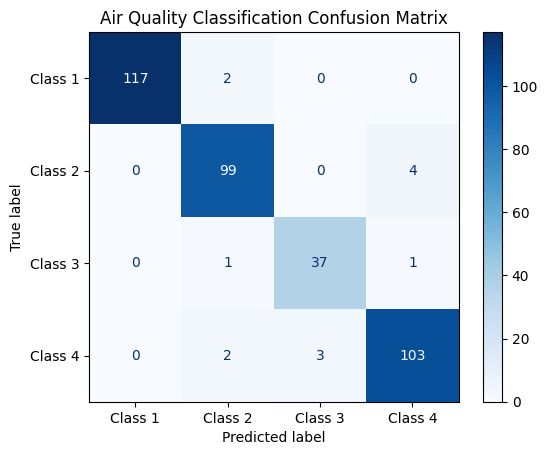

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Train best model
best_model = RandomForestClassifier(random_state=42)
best_model.fit(X_train, y_train)

# Predictions
y_pred = best_model.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Class 1", "Class 2", "Class 3", "Class 4"]
)

display.plot(cmap="Blues")
plt.title("Air Quality Classification Confusion Matrix")
plt.show()

     Feature  Importance
4  Feature_5    0.190649
1  Feature_2    0.186716
2  Feature_3    0.180532
3  Feature_4    0.173501
0  Feature_1    0.137104
5  Feature_6    0.131497


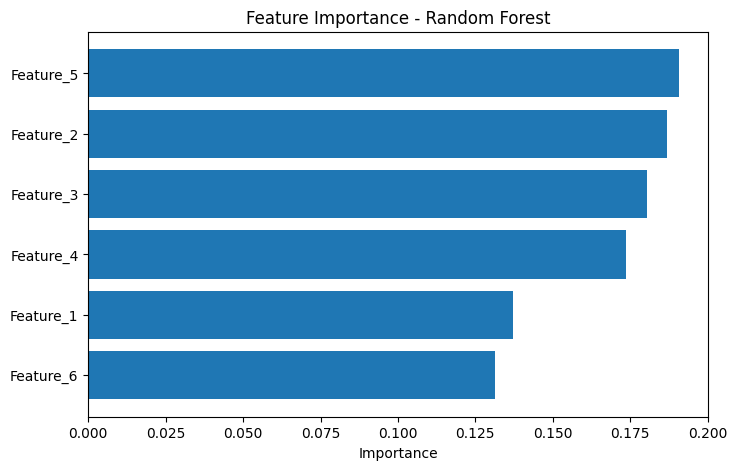

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_model.feature_importances_
})

# Sort values
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

# Plot
plt.figure(figsize=(8,5))
plt.barh(importance["Feature"], importance["Importance"])
plt.gca().invert_yaxis()
plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.show()

In [ ]:
import joblib

joblib.dump(best_model, "air_quality_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
# # Air Quality Classification - Project Summary

# ## Problem Statement
# The goal of this project is to build a machine learning classification model that predicts air quality categories using environmental feature measurements.

# ## Dataset
# The dataset contains 1845 records with 6 numerical features and 4 air quality classes.

# ## Models Used
# - Logistic Regression
# - Decision Tree Classifier
# - Random Forest Classifier

# ## Best Model
# Random Forest Classifier achieved the best performance.

# ## Performance
# - Test Accuracy: 96.5%

# ## Feature Importance
# The most important features were:
# - Feature_5
# - Feature_2
# - Feature_3
# - Feature_4

# ## Conclusion
# The model successfully classifies air quality levels with high accuracy. This project demonstrates a complete machine learning workflow from data preparation to model evaluation and prediction.